# Этап 07. Кластеризация экономических сетей муниципалитетов

## 1. Цель и исходные данные

**Цель этапа** — сопоставить классический и два графовых подхода к выделению экономически сходных муниципалитетов. Рассматриваются разбиения **внутри каждого месяца**; сопоставление кластеров между месяцами и анализ их переходов относятся к этапу 08.

Используются подготовленные на предыдущих этапах данные:

- `X_dynamic` — потребительские доли 2016 муниципалитетов за 24 месяца (шесть категорий в каждом месяце);
- 24 взвешенных графа **CLR + union kNN, k = 10** из этапа 06;
- `manifest.json` — порядок муниципалитетов, месяцы и параметры построения графов.

Годовые показатели `X_annual` и `X_delta` **не участвуют в текущем построении меток**. Их экономическую роль проверим в отдельном дополнении 07А до исследования динамики кластеров.

## 2. Математическая постановка и методы

Для месяца $t$ задан атрибутированный граф

$$
G_t=(V,E_t,W_t,X_t),
$$

где $V$ — фиксированное множество из $n=2016$ муниципалитетов; $E_t$ — связи экономического сходства; $W_t=(w_{ij,t})$ — симметричная матрица их весов; $X_t\in\mathbb{R}^{n\times6}$ — месячные признаки в CLR-пространстве. Требуется получить метку $z_{i,t}$ для каждого муниципалитета $i$.

**K-Means** минимизирует сумму внутрикластерных квадратов расстояний в пространстве атрибутов:

$$
\min_{z,\mu}\;\sum_{i=1}^{n}\left\|x_{i,t}-\mu_{z_{i,t}}\right\|_2^2,
$$

где $\mu_k$ — центр кластера $k$. Метод не использует граф напрямую.

**Spectral Clustering** получает сходство из $W_t$ и использует нормированный лапласиан

$$
L_{\mathrm{sym},t}=I-D_t^{-1/2}W_tD_t^{-1/2},\qquad
(D_t)_{ii}=\sum_jw_{ij,t}.
$$

Разбиение строится по спектральному представлению вершин.

**Leiden** выделяет сообщества взвешенного графа. Используется `RBConfigurationVertexPartition`, для которой оптимизируемая функция, с точностью до положительного множителя, имеет вид

$$
Q_{\gamma}(z)\propto\sum_{i,j}\left(w_{ij,t}-\gamma\frac{s_{i,t}s_{j,t}}{\sum_v s_{v,t}}\right)\mathbf1[z_{i,t}=z_{j,t}],
$$

где $s_{i,t}=\sum_jw_{ij,t}$ — сила вершины, а $\gamma$ — параметр разрешения.

Два графовых метода используют **одни и те же** $W_t$; K-Means использует соответствующие $X_t$. Это сравнение различающихся принципов кластеризации на согласованных исходных данных.

## 3. Критерии качества и план эксперимента

Оценка всех разбиений выполняется в общем месячном CLR-пространстве и на одном и том же взвешенном графе.

**Silhouette** измеряет компактность и разделимость кластеров:

$$
s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}},
$$

где $a(i)$ — среднее расстояние до точек собственного кластера, а $b(i)$ — наименьшее среднее расстояние до другого кластера. Для вычислительной экономии силуэт оценивается на воспроизводимой подвыборке из 500 муниципалитетов (одинаковой для методов и запусков).

**Индекс Калински — Харабаса** вычисляется на всех муниципалитетах:

$$
\mathrm{CH}=\frac{\operatorname{tr}(B)/(K-1)}{\operatorname{tr}(S_W)/(n-K)},
$$

где $B$ и $S_W$ — соответственно межкластерная и внутрикластерная матрицы рассеяния, $K$ — число кластеров.

**Модулярность** оценивает согласованность разбиения с рёбрами графа:

$$
Q=\frac{1}{2m}\sum_{i,j}\left(w_{ij,t}-\frac{s_{i,t}s_{j,t}}{2m}\right)\mathbf1[z_{i,t}=z_{j,t}],
\qquad 2m=\sum_{i,j}w_{ij,t}.
$$

Дополнительно фиксируются **число и размеры кластеров**, доля крупнейшего кластера и **ARI между повторными запусками** (стабильность относительно `random_state`). У метрик разные цели: максимум одного критерия не гарантирует лучшую экономическую типологию.

Сначала параметры оцениваются на четырёх контрольных месяцах, затем выбранные настройки проверяются на всех 24. Выбор ретроспективный: это **не эксперимент по прогнозированию будущего**.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.feature_analysis import parse_dynamic_columns
from src.graph_construction import feature_at
from src.cluster_models import (read_graph_sequence, evaluate_grid, add_repeatability,
                                selected_labels, export_results)

cfg = json.loads((ROOT/'configs'/'clustering_experiment.json').read_text(encoding='utf-8'))
X_dynamic = pd.read_parquet(ROOT/cfg['feature_path'])
mapping = parse_dynamic_columns(X_dynamic)
months = [str(m) for m in sorted({m for m, _ in mapping})]
assert X_dynamic.shape == (2016,144) and len(months) == 24
assert X_dynamic.index.is_unique and not X_dynamic.index.hasnans
print('Матрица:', X_dynamic.shape, '| Период:', months[0], '—', months[-1])

Матрица: (2016, 144) | Период: 2023-01 — 2024-12


## 4. Загрузка матриц и проверка согласованности

Загружаются сохранённые графы этапа 06. Перед расчётом проверяются число и порядок месяцев, число вершин и **точное соответствие идентификаторов муниципалитетов** индексу `X_dynamic` и манифесту. Автоматическая перестановка строк не допускается.

In [2]:
graph_dir = ROOT / cfg['graph_directory']
if not (graph_dir/'manifest.json').is_file():
    raise FileNotFoundError(f'Не найден {graph_dir/"manifest.json"}. Сначала выполните сохранение 24 графов на шаге 06.')
graphs = read_graph_sequence(graph_dir, X_dynamic.index, months)
assert len(graphs) == 24
print('Загружено графов:', len(graphs), '| Размер:', graphs[months[0]].shape,
      '| Рёбер в первом месяце:', graphs[months[0]].nnz//2)

Загружено графов: 24 | Размер: (2016, 2016) | Рёбер в первом месяце: 13929


## 5. Пилотный подбор параметров

На контрольных месяцах **2023-01, 2023-08, 2024-04 и 2024-12** сравниваются:

- K-Means и Spectral Clustering: $K\in\{4,6,8,10\}$;
- Leiden: $\gamma\in\{0.3,0.5,0.8,1.2,1.8\}$;
- для каждого варианта: три случайных состояния (`11`, `42`, `73`).

Число кластеров для Leiden определяется алгоритмом и не обязано совпадать с $K$ других методов. Оцениваются атрибутивное качество, модулярность, устойчивость и баланс размеров; таблица ниже представляет медианы по контрольным запускам.

In [3]:
pilot_months = [months[i] for i in cfg['pilot_month_indices']]
print('Контрольные месяцы:', pilot_months)
pilot, pilot_labels = evaluate_grid(
    X_dynamic, mapping, pilot_months, graphs, cfg['candidate_parameters'],
    cfg['seeds'], cfg['zero_floor'], cfg['silhouette_sample_size'], keep_labels=True)
pilot = add_repeatability(pilot, pilot_labels)
pilot_summary = (pilot.groupby(['method','parameter'], as_index=False)
    .agg(silhouette=('silhouette','median'), calinski_harabasz=('calinski_harabasz','median'),
         modularity=('modularity','median'), ari_repeats=('ari_repeats','median'),
         clusters=('clusters','median'), largest_share=('largest_share','median'),
         size_min=('size_min','median')))
display(pilot_summary.round(3))

Контрольные месяцы: ['2023-01', '2023-08', '2024-04', '2024-12']


,method,parameter,silhouette,calinski_harabasz,modularity,ari_repeats,clusters,largest_share,size_min
0,kmeans,4.0,0.303,1580.943,0.634,0.997,4.0,0.327,312.5
1,kmeans,6.0,0.253,1264.214,0.696,0.964,6.0,0.240,95.0
2,kmeans,8.0,0.222,1088.943,0.723,0.947,8.0,0.179,69.5
3,kmeans,10.0,0.210,958.836,0.720,0.859,10.0,0.148,48.5
4,leiden,0.3,0.213,734.637,0.712,0.735,7.0,0.378,2.0
5,leiden,0.5,0.146,671.425,0.763,0.682,10.0,0.261,2.0
6,leiden,0.8,0.127,606.721,0.780,0.700,13.0,0.174,2.0
7,leiden,1.2,0.105,520.987,0.783,0.617,17.0,0.142,2.0
8,leiden,1.8,0.084,428.161,0.776,0.628,23.0,0.111,2.0
9,spectral,4.0,0.431,24.327,0.001,1.000,4.0,0.993,1.5


## 6. Выбор параметров для полного сравнения

Воспроизводимое правило предварительного отбора — **максимум медианного Silhouette отдельно внутри каждого метода** с учётом ARI при равенстве значений. По пилотной таблице получены:

- K-Means: $K=4$;
- Leiden: $\gamma=0.3$;
- Spectral Clustering: $K=4$.

Это **рабочие параметры**, а не утверждение об их общей оптимальности. В частности, пилотный Spectral при $K=4$ имел высокое значение Silhouette, но крупнейший кластер составлял около 99,3% муниципалитетов; такой дисбаланс необходимо учитывать при анализе полной выборки.

In [4]:
suggested = {method: float(part.sort_values(['silhouette','ari_repeats'], ascending=False).iloc[0]['parameter'])
             for method, part in pilot_summary.groupby('method')}
selected = dict(suggested)  # После анализа пилотной таблицы можно изменить вручную.
print('Предложенные параметры:', suggested)
print('Параметры полного эксперимента:', selected)
assert set(selected)=={'kmeans','spectral','leiden'}

Предложенные параметры: {'kmeans': 4.0, 'leiden': 0.3, 'spectral': 4.0}
Параметры полного эксперимента: {'kmeans': 4.0, 'leiden': 0.3, 'spectral': 4.0}


## 7. Сравнение методов за все 24 месяца

Для трёх методов с выбранными параметрами выполняются по три запуска на каждый месяц: всего **24 × 3 × 3 = 216** наборов метрик. На итоговой таблице представлены медианные показатели по месяцам и запускам.

Для оценки ARI метки всех запусков хранятся в памяти. При сохранении результатов используется **один фиксированный `random_state`** для каждого метода и месяца; переносить числовые номера кластеров между месяцами без согласования нельзя.

In [5]:
full, full_labels = evaluate_grid(
    X_dynamic, mapping, months, graphs,
    {m:[p] for m,p in selected.items()}, cfg['seeds'],
    cfg['zero_floor'], cfg['silhouette_sample_size'], keep_labels=True)
full = add_repeatability(full, full_labels)
comparison = (full.groupby('method', as_index=False)
    .agg(silhouette=('silhouette','median'), calinski_harabasz=('calinski_harabasz','median'),
         modularity=('modularity','median'), ari_repeats=('ari_repeats','median'),
         clusters=('clusters','median'), largest_share=('largest_share','median'),
         size_min=('size_min','median')))
display(comparison.round(3))
print('Строк рассчитанных метрик:', len(full))

,method,silhouette,calinski_harabasz,modularity,ari_repeats,clusters,largest_share,size_min
0,kmeans,0.302,1619.649,0.636,0.995,4.0,0.334,298.5
1,leiden,0.204,738.951,0.715,0.606,6.0,0.388,2.0
2,spectral,0.333,428.813,0.455,1.000,4.0,0.704,3.0


Строк рассчитанных метрик: 216


## 8. Визуальная диагностика

Графики показывают число кластеров и значение Silhouette по месяцам, а также распределение размеров кластеров в **декабре 2024 года**. По ним оцениваются неоднородность структуры и возможное доминирование отдельных сообществ. Изменение номеров кластеров во времени здесь не трактуется как переход муниципалитетов — это задача этапа 08.

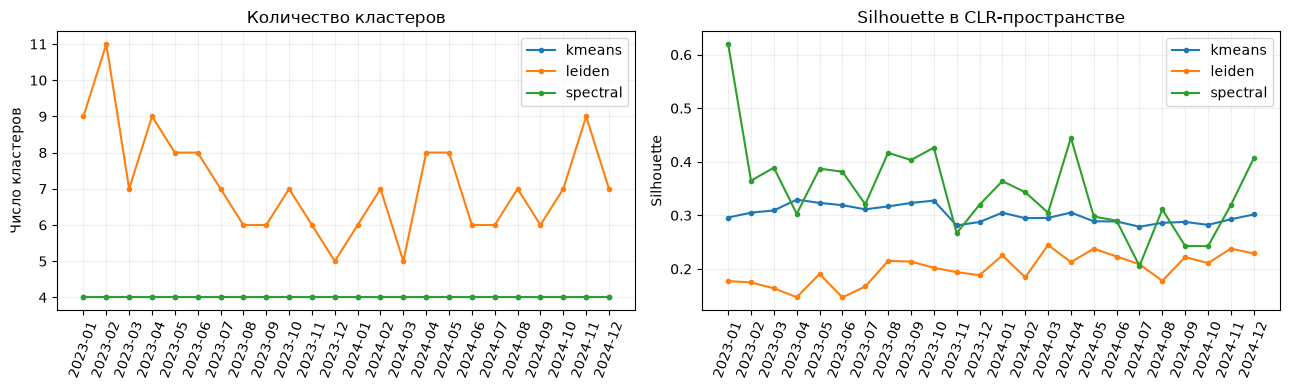

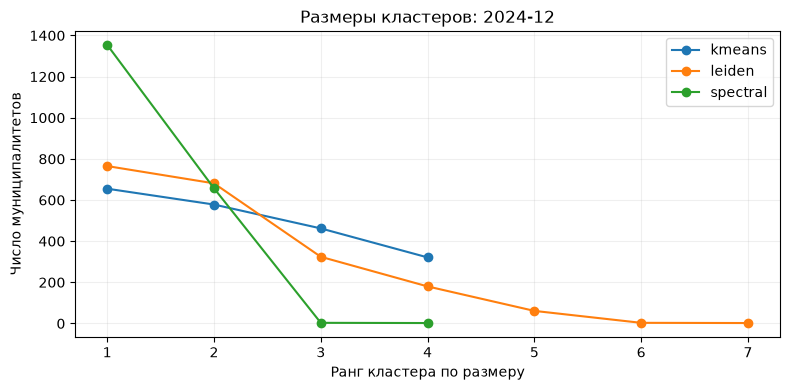

In [6]:
base_seed = cfg['seeds'][0]
plot_frame = full.query('seed == @base_seed').copy()
fig, axes = plt.subplots(1,2,figsize=(13,4))
for method, part in plot_frame.groupby('method'):
    part = part.sort_values('month')
    axes[0].plot(part['month'],part['clusters'],marker='.',label=method)
    axes[1].plot(part['month'],part['silhouette'],marker='.',label=method)
axes[0].set(title='Количество кластеров',ylabel='Число кластеров')
axes[1].set(title='Silhouette в CLR-пространстве',ylabel='Silhouette')
for ax in axes: ax.tick_params(axis='x',rotation=70); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

month_example=months[-1]
fig,ax=plt.subplots(figsize=(8,4))
for method in selected:
    lab=full_labels[(month_example,method,float(selected[method]),int(base_seed))]
    sizes=np.sort(np.unique(lab,return_counts=True)[1])[::-1]
    ax.plot(np.arange(1,len(sizes)+1),sizes,marker='o',label=method)
ax.set(xlabel='Ранг кластера по размеру',ylabel='Число муниципалитетов',
       title=f'Размеры кластеров: {month_example}')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()

## 9. Анализ результатов и предварительный выбор метода

Выполнены все 24 месячных эксперимента; сохранённая таблица содержит **216 строк метрик**. Для рабочих параметров $K=4$ (K-Means), $\gamma=0.3$ (Leiden) и $K=4$ (Spectral) получены следующие медианные значения:

| Критерий | K-Means | Leiden | Spectral |
|:--|--:|--:|--:|
| Silhouette | 0,302 | 0,204 | **0,333** |
| Calinski–Harabasz | **1619,649** | 738,951 | 428,813 |
| Модулярность | 0,636 | **0,715** | 0,455 |
| ARI между запусками | 0,995 | 0,606 | **1,000** |
| Число кластеров | 4 | 6 | 4 |
| Доля крупнейшего кластера | 33,4% | 38,8% | 70,4% |
| Минимальный размер кластера | 298,5 | 2 | 3 |

**K-Means.** Показывает наиболее высокий индекс Калински — Харабаса, почти полную устойчивость к начальной инициализации (ARI 0,995) и относительно сбалансированные группы. Его ограничение — отсутствие непосредственного использования рёбер графа.

**Leiden.** Даёт наибольшую графовую модулярность (0,715), то есть лучше согласуется со структурой связей по этому критерию. Однако медианный минимальный размер сообщества составляет два муниципалитета, а ARI 0,606 указывает на заметную зависимость результата от случайного запуска.

**Spectral Clustering.** Достигает наибольшего Silhouette (0,333) и ARI 1,000, но крупнейший кластер охватывает в медианном месяце 70,4% муниципалитетов при наличии сообществ из нескольких объектов. Таким образом, высокая повторяемость не устраняет проблему дисбаланса.

**Предварительное решение.** Для дальнейшего исследования экономической типологии **K-Means принимается основным базовым кандидатом** по совокупности атрибутивного качества, воспроизводимости и баланса размеров. **Leiden сохраняется как ключевая графовая альтернатива**, позволяющая проверить добавочную ценность сетевых связей; Spectral — как сравнительный метод. Окончательный выбор не делается до анализа годовых экономических характеристик и расчёта конкурсных ICVI на этапе 09.

Ограничения: Silhouette оценивался на фиксированной подвыборке; показатели качества отражают разные аспекты разбиения; ретроспективный отбор параметров не доказывает способность метода прогнозировать будущие экономические изменения.

## 10. Сохранение результатов и переход к этапу 07А

Результаты записаны в `outputs/bdmo_v3/clustering_step07/`:

- `labels.parquet` — метки K-Means, Leiden и Spectral для 24 месяцев с исходным индексом муниципалитетов;
- `metrics.parquet` — рассчитанные показатели качества;
- `experiment.json` — параметры запуска и отбора моделей.


In [7]:
labels = selected_labels(full_labels, months, selected, cfg['seeds'], X_dynamic.index)
assert labels.index.equals(X_dynamic.index)
assert labels.shape == (len(X_dynamic), 24*3)
export_results(ROOT/cfg['output_directory'], labels, full, cfg, selected)
print('Результаты сохранены:', ROOT/cfg['output_directory'])

Результаты сохранены: /Users/olgakan/vlad/hack/outputs/bdmo_v3/clustering_step07
